# 04 – Dự báo khách mua lại trong 90 ngày (W11)
Ba snapshot hồi cứu: train 01/03/2011, validation 01/06/2011, test 01/09/2011. Cửa sổ nhãn 90 ngày không chồng lấn. Feature chỉ sử dụng lịch sử trước từng cutoff. Khách hàng có thể xuất hiện ở nhiều snapshot vì mục tiêu là dự báo lại cho khách đã biết; không đánh giá cold-start. Test tháng 9 từng được xem ở P0, do đó đây là kiểm chứng theo thời gian hồi cứu, không phải tập hoàn toàn chưa từng tiếp cận. Không tối ưu mô hình/threshold dựa trên test mới.

In [1]:
from pathlib import Path
import sys
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p/'src'/'classification_evaluation.py').is_file()), None)
if ROOT is None: raise FileNotFoundError('Mở notebook bên trong repository.')
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.pipeline import run_pipeline
from src.classification_evaluation import (CUTOFFS, FEATURES, TARGET, temporal_datasets, split_xy,
                                            select_model, choose_threshold, evaluate_probabilities)
PROCESSED = ROOT/'data/processed'
REPORTS = ROOT/'reports'
FIGURES = REPORTS/'figures'
FIGURES.mkdir(parents=True,exist_ok=True)
observed_until = run_pipeline(ROOT/'data/raw', PROCESSED, REPORTS)
transactions = pd.read_parquet(PROCESSED/'retail_processed.parquet')
snapshots = temporal_datasets(transactions, observed_until)
del transactions
rows = []
for (role,data), cutoff in zip(snapshots.items(), CUTOFFS):
    data.to_parquet(PROCESSED/f'customer_modeling_{role}.parquet',index=False)
    rows.append({'role':role,'cutoff':cutoff,'label_end_exclusive':pd.Timestamp(cutoff)+pd.Timedelta(days=90),
                 'customers':len(data),'repeat_share':data[TARGET].mean()})
snapshots['test'].to_parquet(PROCESSED/'customer_modeling_dataset.parquet',index=False)
display(pd.DataFrame(rows))
print('Observed until:',observed_until)
print('Khách trùng train/test:',len(set(snapshots['train']['customer_id']) & set(snapshots['test']['customer_id'])))
X_train,y_train = split_xy(snapshots['train'])
X_val,y_val = split_xy(snapshots['validation'])
X_test,y_test = split_xy(snapshots['test'])

1. Đang đọc dữ liệu gốc...
Nguồn: online_retail_II.csv | 1,067,371 dòng
2. Đang làm sạch dữ liệu & tạo Cleaning Log...
3. Đang tích hợp nguồn dữ liệu phụ (Merge)...
[Merge 1 - Country Metadata] Trước: 794,437 | Sau: 794,437 | Tỷ lệ khớp: 99.71%
  -> Các giá trị chưa khớp (2,273 dòng): ['Channel Islands', 'Unspecified', 'West Indies', 'European Community']
[Merge 2 - Season Calendar]  Trước: 794,437 | Sau: 794,437 | Tỷ lệ khớp: 100.00%
4. Hoàn tất! Đã lưu 794,437 dòng vào 'c:\Code\KHDL\Project 2\data\processed\retail_processed.parquet' và cập nhật 'c:\Code\KHDL\Project 2\reports/cleaning_log.csv'.


,role,cutoff,label_end_exclusive,customers,repeat_share
0,train,2011-03-01,2011-05-30,4513,0.351208
1,validation,2011-06-01,2011-08-30,4909,0.329395
2,test,2011-09-01,2011-11-30,5225,0.427943


Observed until: 2011-12-09 12:50:00
Khách trùng train/test: 4513


## 1. Lựa chọn mô hình trên train
Primary metric: ROC-AUC (khả năng xếp hạng khách mua lại, không phụ thuộc threshold). Nếu hòa, dùng Average Precision rồi tên mô hình. CV phân tầng trong snapshot train; không dùng validation/test để lựa chọn ứng viên. Preprocessor được fit trong từng fold.

In [2]:
cv_results, best_name, best_pipe = select_model(X_train,y_train)
display(cv_results.round(4))
print('Mô hình được chọn theo ROC-AUC CV:',best_name)
cv_results.to_csv(REPORTS/'classification_cv.csv',index=False)

,model,roc_auc_mean,roc_auc_sd,ap_mean,f1_mean,accuracy_mean,folds
0,Random Forest,0.7906,0.0095,0.7177,0.6338,0.7399,5
1,Logistic Regression,0.7885,0.0102,0.7101,0.6438,0.7303,5
2,HistGradientBoosting,0.7803,0.0048,0.7014,0.5893,0.7525,5
3,k-NN,0.7766,0.0134,0.6940,0.5961,0.7527,5
4,Gaussian Naive Bayes,0.7624,0.0202,0.6497,0.5446,0.4392,5
5,Dummy Baseline,0.5000,0.0000,0.3512,0.0000,0.6488,5


Mô hình được chọn theo ROC-AUC CV: Random Forest


## 2. Khóa threshold trên validation, đánh giá trên test
Fit train tháng 3, tối ưu F1 trên validation tháng 6 (vì chưa có chi phí FP/FN thực). Giữ nguyên cả model lẫn threshold để dự báo snapshot tháng 9. Không refit trên validation sau khi chọn ngưỡng. Báo cáo baseline và cả threshold mặc định. Không điều chỉnh tiếp dựa trên kết quả test.

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, roc_curve, precision_recall_curve, ConfusionMatrixDisplay
best_pipe.fit(X_train,y_train)
val_probs = best_pipe.predict_proba(X_val)[:,1]
optimal_threshold, validation_f1 = choose_threshold(y_val,val_probs)
print(f'Validation threshold={optimal_threshold:.4f}; F1={validation_f1:.4f}')
test_probs = best_pipe.predict_proba(X_test)[:,1]
test_preds = (test_probs >= optimal_threshold).astype(int)
baseline = DummyClassifier(strategy='most_frequent').fit(X_train,y_train)
baseline_probs = baseline.predict_proba(X_test)[:,1]
metrics = pd.DataFrame([
    {'model':'Dummy Baseline','split':'test',**evaluate_probabilities(y_test,baseline_probs,.5)},
    {'model':best_name,'split':'validation',**evaluate_probabilities(y_val,val_probs,optimal_threshold)},
    {'model':best_name,'split':'test_default',**evaluate_probabilities(y_test,test_probs,.5)},
    {'model':best_name,'split':'test_tuned',**evaluate_probabilities(y_test,test_probs,optimal_threshold)},
])
# F1/accuracy tại ngưỡng mặc định của baseline tương ứng predict most_frequent;
# trường hợp lớp hòa, DummyClassifier trả lớp nhỏ hơn (probability 0/1).
display(metrics.round(4))
print(classification_report(y_test,test_preds,digits=4,zero_division=0))
metrics.to_csv(REPORTS/'classification_temporal_metrics.csv',index=False)

Validation threshold=0.4805; F1=0.6602


,model,split,threshold,accuracy,precision,recall,f1,roc_auc,average_precision,prevalence
0,Dummy Baseline,test,0.5000,0.5721,0.0000,0.0000,0.0000,0.5000,0.4279,0.4279
1,Random Forest,validation,0.4805,0.7659,0.6327,0.6902,0.6602,0.8204,0.7257,0.3294
2,Random Forest,test_default,0.5000,0.7319,0.7342,0.5854,0.6514,0.7936,0.7639,0.4279
3,Random Forest,test_tuned,0.4805,0.7301,0.7190,0.6064,0.6579,0.7936,0.7639,0.4279


              precision    recall  f1-score   support

           0     0.7364    0.8227    0.7772      2989
           1     0.7190    0.6064    0.6579      2236

    accuracy                         0.7301      5225
   macro avg     0.7277    0.7146    0.7176      5225
weighted avg     0.7290    0.7301    0.7261      5225



## 3. Đường cong và ma trận nhầm lẫn trên test theo thời gian

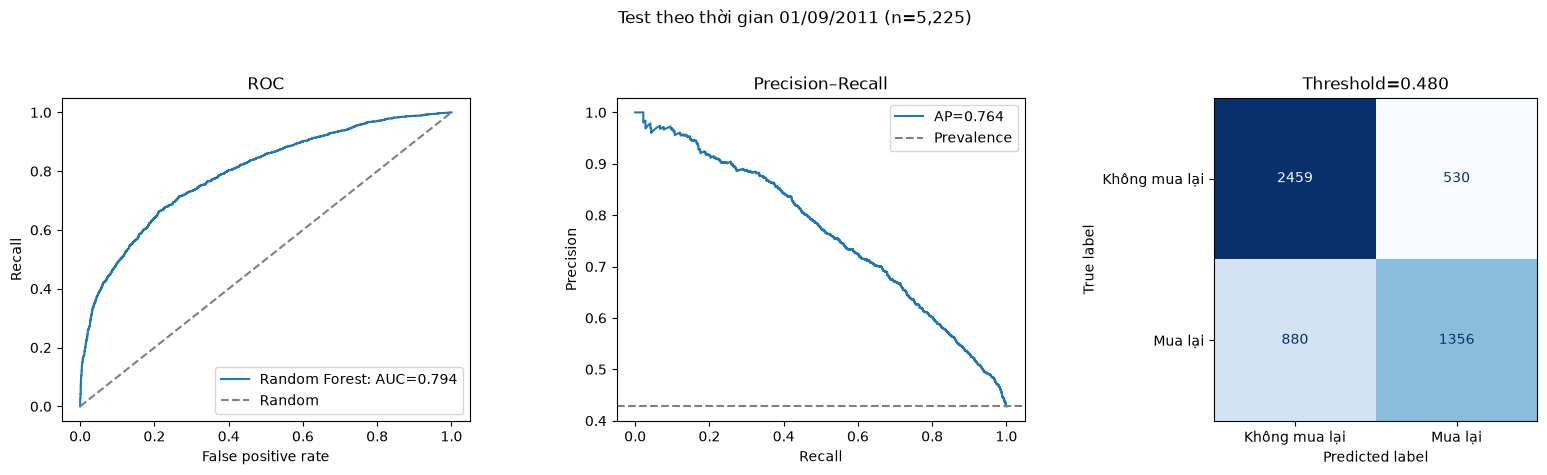

In [4]:
fig,axes = plt.subplots(1,3,figsize=(16,4.8))
fpr,tpr,_ = roc_curve(y_test,test_probs)
auc = metrics.loc[metrics['split']=='test_tuned','roc_auc'].iloc[0]
axes[0].plot(fpr,tpr,label=f'{best_name}: AUC={auc:.3f}')
axes[0].plot([0,1],[0,1],'--',color='gray',label='Random')
axes[0].set(title='ROC',xlabel='False positive rate',ylabel='Recall'); axes[0].legend()
precision,recall,_ = precision_recall_curve(y_test,test_probs)
ap = metrics.loc[metrics['split']=='test_tuned','average_precision'].iloc[0]
axes[1].plot(recall,precision,label=f'AP={ap:.3f}')
axes[1].axhline(y_test.mean(),color='gray',linestyle='--',label='Prevalence')
axes[1].set(title='Precision–Recall',xlabel='Recall',ylabel='Precision'); axes[1].legend()
ConfusionMatrixDisplay.from_predictions(y_test,test_preds,labels=[0,1],display_labels=['Không mua lại','Mua lại'],ax=axes[2],colorbar=False,cmap='Blues')
axes[2].set_title(f'Threshold={optimal_threshold:.3f}')
fig.suptitle(f'Test theo thời gian 01/09/2011 (n={len(y_test):,})')
fig.tight_layout(rect=[0,0,1,.94])
fig.savefig(FIGURES/'05_classification_evaluation.png',dpi=300,bbox_inches='tight')
plt.show()

## 4. Permutation Importance
Đo giảm ROC-AUC khi hoán vị từng cột gốc trên validation, với pipeline đã fit cố định. Không dùng kết quả này để chọn lại mô hình hoặc đặc trưng. Feature tương quan mạnh có thể chia sẻ độ quan trọng; đây không phải quan hệ nhân quả. Giá trị âm có thể do nhiễu.

,feature,auc_drop_mean,auc_drop_sd
0,recency_days,0.0211,0.0026
8,purchase_rate_per_30d,0.0133,0.0023
2,frequency,0.0080,0.0021
9,interpurchase_mean_days,0.0036,0.0007
5,gross_valid_revenue,0.0029,0.0016
3,total_items,0.0028,0.0011
12,peak_month_ratio,0.0012,0.0002
14,items_per_sku,0.0010,0.0005
6,avg_order_value,0.0008,0.0004
1,observation_span_days,0.0004,0.0004


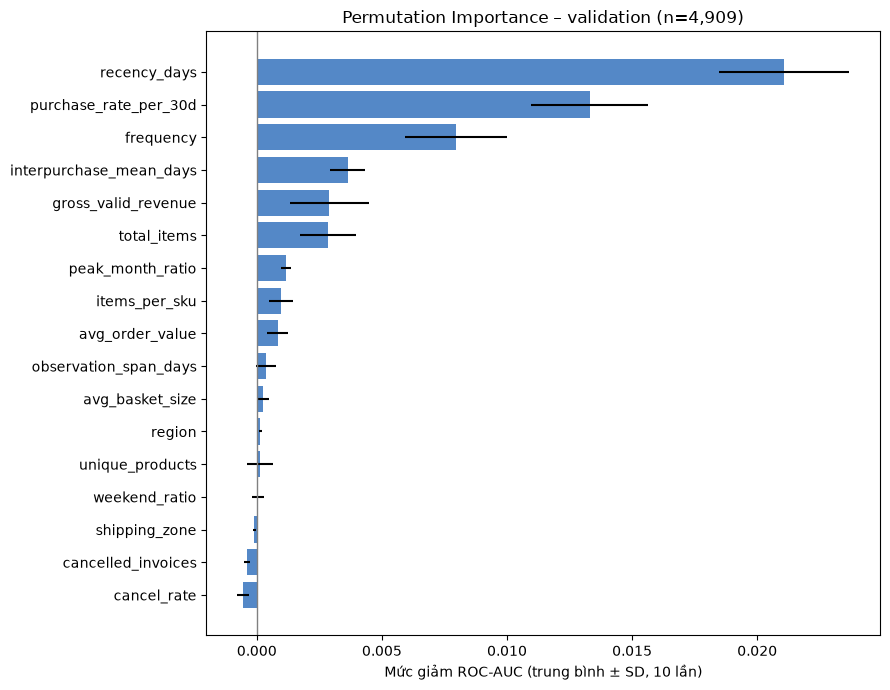

In [5]:
from sklearn.inspection import permutation_importance
perm = permutation_importance(best_pipe,X_val,y_val,scoring='roc_auc',n_repeats=10,random_state=42,n_jobs=1)
importance = pd.DataFrame({'feature':FEATURES,'auc_drop_mean':perm.importances_mean,'auc_drop_sd':perm.importances_std}).sort_values('auc_drop_mean',ascending=False)
display(importance.round(4))
importance.to_csv(REPORTS/'classification_feature_importance.csv',index=False)
plot = importance.iloc[::-1]
fig,ax = plt.subplots(figsize=(9,7))
ax.barh(plot['feature'],plot['auc_drop_mean'],xerr=plot['auc_drop_sd'],color='#5488C7')
ax.axvline(0,color='gray',lw=1)
ax.set(title=f'Permutation Importance – validation (n={len(y_val):,})',xlabel='Mức giảm ROC-AUC (trung bình ± SD, 10 lần)')
fig.tight_layout()
fig.savefig(FIGURES/'06_classification_feature_importance.png',dpi=300,bbox_inches='tight')
plt.show()